# Projet Data Analyst — Sales & Business Performance Cameroon 🇨🇲

## Structure du workflow

**Base SQL → SQL → Python/Pandas → Visualisation → Recommandations métier → Power BI**

Ce notebook montre explicitement **où SQL intervient** et où Python prend le relais.

**Jeu de données : 5 000 transactions synthétiques**, cohérent avec la base SQLite, le fichier Excel et le projet Power BI de ce repository.


# 0. Connexion à SQLite

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Repository structure:
# notebooks/Projet_01_SQL_Python.ipynb
# data/database/sales_performance_cameroon.db
DB_PATH = Path("../data/database/sales_performance_cameroon.db")

if not DB_PATH.exists():
    raise FileNotFoundError(
        "Base SQLite introuvable. Lancez ce notebook depuis le dossier notebooks "
        "du repository ou vérifiez data/database/sales_performance_cameroon.db."
    )

con = sqlite3.connect(DB_PATH)
print("Connexion réussie :", DB_PATH.resolve())


Connexion réussie : ../data/database/sales_performance_cameroon.db


# PARTIE 1 — SQL

Ici, **SQL fait l'analyse**. Python sert seulement à envoyer la requête et afficher le résultat avec `pd.read_sql_query()`.


## 1.1 SELECT — voir les données

In [2]:
query = """
SELECT *
FROM fact_sales
LIMIT 10;
"""
pd.read_sql_query(query, con)

,transaction_id,date_vente,store_id,customer_id,product_id,salesperson_id,canal,mode_paiement,quantite,prix_unitaire_fcfa,taux_remise,cout_unitaire_fcfa,ventes_brutes_fcfa,montant_remise_fcfa,ca_net_fcfa,cout_total_fcfa,marge_brute_fcfa,taux_marge
0,T00001,2025-08-01,STR005,C0033,P026,SP017,Boutique,Espèces,4,4850,0.05,3000,19400.0,970.0,18430.0,12000.0,6430.0,0.348888
1,T00002,2024-12-21,STR002,C0287,P015,SP006,Boutique,Orange Money,2,18250,0.02,12600,36500.0,730.0,35770.0,25200.0,10570.0,0.295499
2,T00003,2026-05-12,STR003,C0831,P012,SP009,Boutique,MTN MoMo,2,10200,0.05,6500,20400.0,1020.0,19380.0,13000.0,6380.0,0.329205
3,T00004,2024-12-25,STR002,C0205,P018,SP006,WhatsApp / Téléphone,Espèces,1,3250,0.02,2100,3250.0,65.0,3185.0,2100.0,1085.0,0.340659
4,T00005,2025-10-28,STR003,C0729,P028,SP012,WhatsApp / Téléphone,Orange Money,3,4250,0.00,3300,12750.0,0.0,12750.0,9900.0,2850.0,0.223529
5,T00006,2025-02-26,STR002,C0889,P001,SP008,WhatsApp / Téléphone,Virement,3,1550,0.03,950,4650.0,139.5,4510.5,2850.0,1660.5,0.368141
6,T00007,2026-02-11,STR003,C0902,P011,SP010,Boutique,MTN MoMo,2,9200,0.00,5900,18400.0,0.0,18400.0,11800.0,6600.0,0.358696
7,T00008,2025-08-25,STR004,C0451,P002,SP014,Boutique,MTN MoMo,1,12150,0.00,7800,12150.0,0.0,12150.0,7800.0,4350.0,0.358025
8,T00009,2024-07-23,STR002,C0612,P016,SP005,Boutique,MTN MoMo,4,13700,0.00,8800,54800.0,0.0,54800.0,35200.0,19600.0,0.357664
9,T00010,2024-06-23,STR001,C0023,P008,SP002,Boutique,Carte bancaire,4,14200,0.02,9300,56800.0,1136.0,55664.0,37200.0,18464.0,0.331705


## 1.2 KPI — COUNT, SUM, AVG

In [3]:
query = """
SELECT
 COUNT(*) AS transactions,
 ROUND(SUM(ca_net_fcfa),0) AS chiffre_affaires_fcfa,
 ROUND(SUM(marge_brute_fcfa),0) AS marge_brute_fcfa,
 ROUND(100.0*SUM(marge_brute_fcfa)/SUM(ca_net_fcfa),2) AS taux_marge_pct,
 ROUND(AVG(ca_net_fcfa),0) AS panier_moyen_fcfa
FROM fact_sales;
"""
kpi_sql = pd.read_sql_query(query, con)
kpi_sql

,transactions,chiffre_affaires_fcfa,marge_brute_fcfa,taux_marge_pct,panier_moyen_fcfa
0,5000,153404278.0,45758828.0,29.83,30681.0


## 1.3 WHERE — filtrer les ventes 2026 avec remise

In [4]:
query = """
SELECT transaction_id,date_vente,ca_net_fcfa,taux_remise
FROM fact_sales
WHERE date_vente >= '2026-01-01'
  AND taux_remise > 0
ORDER BY ca_net_fcfa DESC
LIMIT 15;
"""
pd.read_sql_query(query, con)

,transaction_id,date_vente,ca_net_fcfa,taux_remise
0,T03909,2026-02-12,366030.0,0.10
1,T01692,2026-04-29,327184.0,0.12
2,T02042,2026-03-12,265762.5,0.05
3,T03525,2026-03-09,242880.0,0.12
4,T01491,2026-01-22,216132.0,0.07
5,T00991,2026-04-19,194194.0,0.03
6,T04152,2026-06-01,186300.0,0.10
7,T00841,2026-06-19,184635.0,0.10
8,T01030,2026-04-24,174800.0,0.05
9,T01812,2026-07-07,170940.0,0.12


## 1.4 GROUP BY — CA par canal

In [5]:
query = """
SELECT canal,
       COUNT(*) AS transactions,
       ROUND(SUM(ca_net_fcfa),0) AS ca_fcfa
FROM fact_sales
GROUP BY canal
ORDER BY ca_fcfa DESC;
"""
canal_sql = pd.read_sql_query(query, con)
canal_sql

,canal,transactions,ca_fcfa
0,Boutique,3826,114162107.0
1,WhatsApp / Téléphone,972,29109577.0
2,B2B,202,10132594.0


## 1.5 JOIN — CA par agence

In [6]:
query = """
SELECT s.ville,
       COUNT(*) AS transactions,
       ROUND(SUM(f.ca_net_fcfa),0) AS ca_fcfa,
       ROUND(SUM(f.marge_brute_fcfa),0) AS marge_fcfa
FROM fact_sales f
JOIN dim_store s
  ON f.store_id = s.store_id
GROUP BY s.ville
ORDER BY ca_fcfa DESC;
"""
ville_sql = pd.read_sql_query(query, con)
ville_sql

,ville,transactions,ca_fcfa,marge_fcfa
0,Douala,1389,42670829.0,12895679.0
1,Yaoundé,1220,36419074.0,11259324.0
2,Bafoussam,956,29954084.0,8736884.0
3,Bamenda,786,23536764.0,6840164.0
4,Dschang,649,20823527.0,6026777.0


## 1.6 JOIN — Top produits

In [7]:
query = """
SELECT p.produit,p.categorie,
       ROUND(SUM(f.ca_net_fcfa),0) AS ca_fcfa,
       ROUND(SUM(f.marge_brute_fcfa),0) AS marge_fcfa
FROM fact_sales f
JOIN dim_product p
  ON f.product_id = p.product_id
GROUP BY p.product_id,p.produit,p.categorie
ORDER BY ca_fcfa DESC
LIMIT 10;
"""
top_produits_sql = pd.read_sql_query(query, con)
top_produits_sql

,produit,categorie,ca_fcfa,marge_fcfa
0,Ventilateur sur pied,Maison,16036834.0,3646834.0
1,Cartouche imprimante,Bureau,9809865.0,2797365.0
2,Calculatrice scientifique,Fournitures scolaires,8745619.0,2825219.0
3,Bouilloire électrique,Maison,8638644.0,2571944.0
4,Sac à dos scolaire,Fournitures scolaires,8617180.0,2837380.0
5,Fer à repasser,Maison,8544405.0,2446005.0
6,Power bank 10000mAh,Électronique,7537746.0,2376246.0
7,Lampe rechargeable,Maison,7231599.0,2400399.0
8,Lait en poudre pack,Alimentation,6679294.0,1392794.0
9,Chargeur rapide,Électronique,6560181.0,2179181.0


## 1.7 CTE + LAG — croissance mensuelle

In [8]:
query = """
WITH ca_mensuel AS (
 SELECT SUBSTR(date_vente,1,7) AS mois,
        SUM(ca_net_fcfa) AS ca
 FROM fact_sales
 GROUP BY mois
),
evolution AS (
 SELECT mois,ca,
        LAG(ca) OVER(ORDER BY mois) AS ca_prec
 FROM ca_mensuel
)
SELECT mois,
       ROUND(ca,0) AS ca_fcfa,
       ROUND(100.0*(ca-ca_prec)/ca_prec,2) AS croissance_mom_pct
FROM evolution
ORDER BY mois;
"""
croissance_sql = pd.read_sql_query(query, con)
croissance_sql.tail(12)

,mois,ca_fcfa,croissance_mom_pct
19,2025-08,4731945.0,7.98
20,2025-09,6182317.0,30.65
21,2025-10,4889708.0,-20.91
22,2025-11,5364365.0,9.71
23,2025-12,7911472.0,47.48
24,2026-01,4158358.0,-47.44
25,2026-02,4094516.0,-1.54
26,2026-03,4588020.0,12.05
27,2026-04,5546522.0,20.89
28,2026-05,4356459.0,-21.46


## 1.8 Vue SQL pour la suite

La vue `vw_sales_analysis` regroupe les tables grâce aux `JOIN`.  
Nous l'utilisons ensuite comme table analytique pour Python.


In [9]:
df = pd.read_sql_query(
    "SELECT * FROM vw_sales_analysis",
    con,
    parse_dates=["date_vente"]
)
df.head()

,transaction_id,date_vente,annee,annee_mois,ville,region,segment_client,categorie,produit,commercial,canal,mode_paiement,quantite,prix_unitaire_fcfa,taux_remise,ca_net_fcfa,marge_brute_fcfa,taux_marge
0,T00001,2025-08-01,2025,2025-08,Bamenda,Nord-Ouest,Particulier,Bureau,Marqueurs tableau,Vanessa Nana,Boutique,Espèces,4,4850,0.05,18430.0,6430.0,0.348888
1,T00002,2024-12-21,2024,2024-12,Yaoundé,Centre,Particulier,Maison,Fer à repasser,Ruth Mballa,Boutique,Orange Money,2,18250,0.02,35770.0,10570.0,0.295499
2,T00003,2026-05-12,2026,2026-05,Bafoussam,Ouest,Particulier,Électronique,Chargeur rapide,Grace Nana,Boutique,MTN MoMo,2,10200,0.05,19380.0,6380.0,0.329205
3,T00004,2024-12-25,2024,2024-12,Yaoundé,Centre,Particulier,Hygiène,Savon liquide 1L,Ruth Mballa,WhatsApp / Téléphone,Espèces,1,3250,0.02,3185.0,1085.0,0.340659
4,T00005,2025-10-28,2025,2025-10,Bafoussam,Ouest,Particulier,Alimentation,Eau minérale pack,Grace Simo,WhatsApp / Téléphone,Orange Money,3,4250,0.00,12750.0,2850.0,0.223529


# PARTIE 2 — Python / Pandas

Ici, Python prend le relais pour le contrôle qualité, les transformations et les analyses complémentaires.


## 2.1 Contrôle qualité

In [10]:
print("Dimensions :", df.shape)
print("Doublons :", df["transaction_id"].duplicated().sum())
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Période :", df["date_vente"].min().date(), "→", df["date_vente"].max().date())

Dimensions : (5000, 18)
Doublons : 0
Valeurs manquantes : 0
Période : 2024-01-01 → 2026-07-31


## 2.2 Même analyse en Pandas

Nous avons déjà calculé le CA par ville en SQL. Voici l'équivalent Pandas.


In [11]:
ville_python = (
    df.groupby("ville", as_index=False)
      .agg(
          chiffre_affaires_fcfa=("ca_net_fcfa","sum"),
          marge_brute_fcfa=("marge_brute_fcfa","sum"),
          transactions=("transaction_id","nunique")
      )
      .sort_values("chiffre_affaires_fcfa", ascending=False)
)
ville_python

,ville,chiffre_affaires_fcfa,marge_brute_fcfa,transactions
2,Douala,42670829.25,12895679.25,1389
4,Yaoundé,36419073.75,11259323.75,1220
0,Bafoussam,29954083.50,8736883.50,956
1,Bamenda,23536764.25,6840164.25,786
3,Dschang,20823527.00,6026777.00,649


## 2.3 Segments clients

In [12]:
segments_python = (
    df.groupby("segment_client", as_index=False)
      .agg(
          chiffre_affaires_fcfa=("ca_net_fcfa","sum"),
          marge_brute_fcfa=("marge_brute_fcfa","sum"),
          panier_moyen_fcfa=("ca_net_fcfa","mean")
      )
)
segments_python

,segment_client,chiffre_affaires_fcfa,marge_brute_fcfa,panier_moyen_fcfa
0,PME,3.064744e+07,9123385.00,29958.391984
1,Particulier,1.087192e+08,32330365.25,31071.496213
2,Revendeur,1.403768e+07,4305077.50,29367.526151


## 2.4 Analyse des remises

In [13]:
df["groupe_remise"] = df["taux_remise"].gt(0).map({True:"Avec remise", False:"Sans remise"})
remises_python = (
    df.groupby("groupe_remise", as_index=False)
      .agg(
          panier_moyen_fcfa=("ca_net_fcfa","mean"),
          quantite_moyenne=("quantite","mean"),
          ca_fcfa=("ca_net_fcfa","sum"),
          marge_fcfa=("marge_brute_fcfa","sum")
      )
)
remises_python["taux_marge"] = remises_python["marge_fcfa"] / remises_python["ca_fcfa"]
remises_python

,groupe_remise,panier_moyen_fcfa,quantite_moyenne,ca_fcfa,marge_fcfa,taux_marge
0,Avec remise,33462.844928,4.177738,1.118328e+08,32180227.75,0.287753
1,Sans remise,25073.250905,2.922195,4.157145e+07,13578600.00,0.326633


## 2.5 Part du Mobile Money

In [14]:
mask = df["mode_paiement"].isin(["MTN MoMo","Orange Money"])
part_mobile_money = df.loc[mask,"ca_net_fcfa"].sum() / df["ca_net_fcfa"].sum()
print(f"Part du CA payée par Mobile Money : {part_mobile_money:.2%}")

Part du CA payée par Mobile Money : 53.97%


# PARTIE 3 — Visualisation

Chaque graphique répond à une question métier.


## 3.1 CA par agence

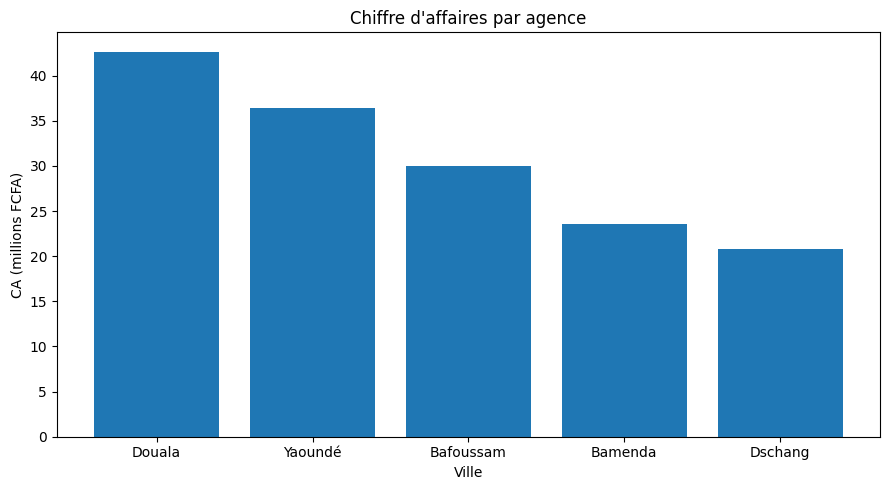

In [15]:
plt.figure(figsize=(9,5))
plt.bar(ville_python["ville"], ville_python["chiffre_affaires_fcfa"]/1_000_000)
plt.title("Chiffre d'affaires par agence")
plt.xlabel("Ville")
plt.ylabel("CA (millions FCFA)")
plt.tight_layout()
plt.show()

## 3.2 Évolution mensuelle

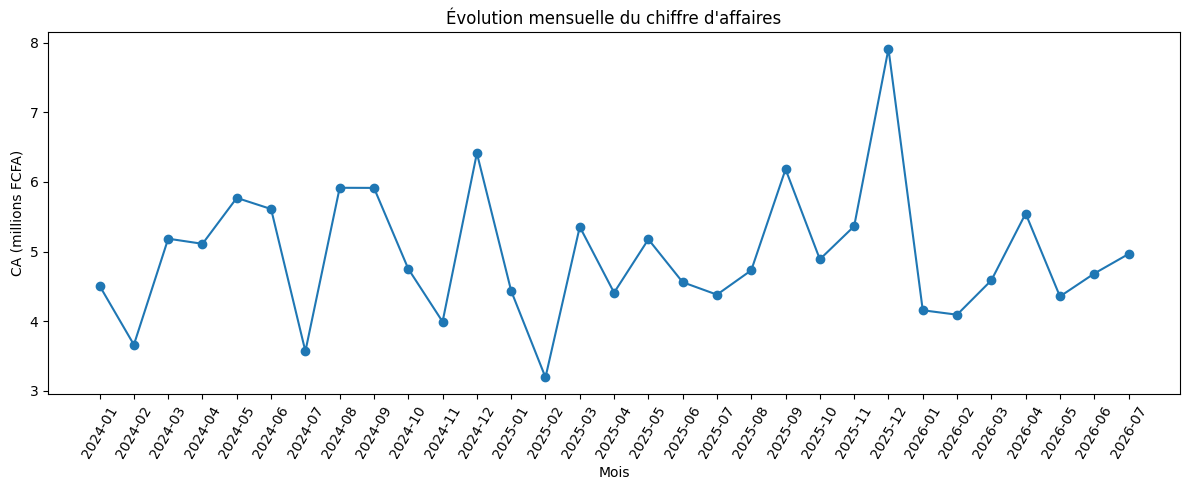

In [16]:
mensuel = (
    df.assign(mois=df["date_vente"].dt.to_period("M").astype(str))
      .groupby("mois", as_index=False)
      .agg(ca_fcfa=("ca_net_fcfa","sum"))
)
plt.figure(figsize=(12,5))
plt.plot(mensuel["mois"],mensuel["ca_fcfa"]/1_000_000,marker="o")
plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("CA (millions FCFA)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# PARTIE 4 — Recommandations métier

À partir des analyses :
- comparer les agences avec **CA + marge + panier moyen** ;
- renforcer les stocks avant les périodes saisonnières fortes ;
- développer les segments PME et revendeurs ;
- traiter le Mobile Money comme un mode de paiement stratégique ;
- surveiller les remises qui dégradent la marge ;
- évaluer les commerciaux sur la rentabilité créée, pas seulement sur le CA.


# PARTIE 5 — Power BI

La prochaine étape sera la restitution décisionnelle.

**KPI :** CA, marge, taux de marge, transactions, panier moyen.

**Visuels :** CA par ville, catégories, top produits, évolution mensuelle, segments clients, paiements, commerciaux.

**Filtres :** année, ville, catégorie, segment, canal, mode de paiement.


# Conclusion

Tu dois pouvoir expliquer le workflow ainsi :

> **SQL** : extraction, filtres, jointures et agrégations.  
> **Python/Pandas** : contrôle qualité et analyses complémentaires.  
> **Matplotlib** : visualisation exploratoire.  
> **Power BI** : dashboard décisionnel.


In [17]:
con.close()
print("Analyse terminée.")

Analyse terminée.
